### Deep Agents overview



Build agents that can plan, use subagents, and leverage file systems for complex tasks

deepagents is a standalone library for building agents that can tackle complex, multi-step tasks. Built on LangGraph and inspired by applications like Claude Code, Deep Research, and Manus, deep agents come with planning capabilities, file systems for context management, and the ability to spawn subagents.


### When to use deep agents
Use deep agents when you need agents that can:

- Handle complex, multi-step tasks that require planning and decomposition
- Manage large amounts of context through file system tools
- Delegate work to specialized subagents for context isolation
- Persist memory across conversations and threads

In [21]:
### Basic deep agent

import os
from dotenv import load_dotenv
load_dotenv()


os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

In [22]:
from typing import Literal

In [39]:
### Tools- Internet search
from tavily import TavilyClient
from typing import Literal

tavily_client=TavilyClient(api_key=os.getenv("TAVILY_API_KEY"))

def web_search(query:str,max_results:int=5,
topic: Literal["general","sports","news","finance"]="general",
include_raw_content:bool=False):
    """Run a web search"""
    return tavily_client.search(query,
    max_results=max_results,include_raw_content=include_raw_content,topic=topic)



In [24]:
from langchain.chat_models import init_chat_model

model = init_chat_model(
    model="qwen/qwen3.8-27b",
    model_provider="groq"
)
model

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.1', 'langchain': '1.5.0', 'langchain-groq': '1.2.0'}}, profile={'name': 'Qwen3.8 27B', 'status': 'beta', 'release_date': '2026-08-14', 'last_updated': '2026-08-14', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000014DE249C5F0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000014DE249E0C0>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********'))

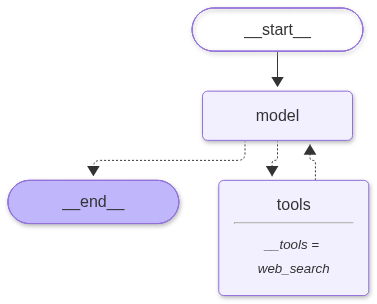

In [25]:
## Basic Agent
from langchain.agents import create_agent


simple_agent=create_agent(
    model=model,
    tools=[web_search]
)
simple_agent

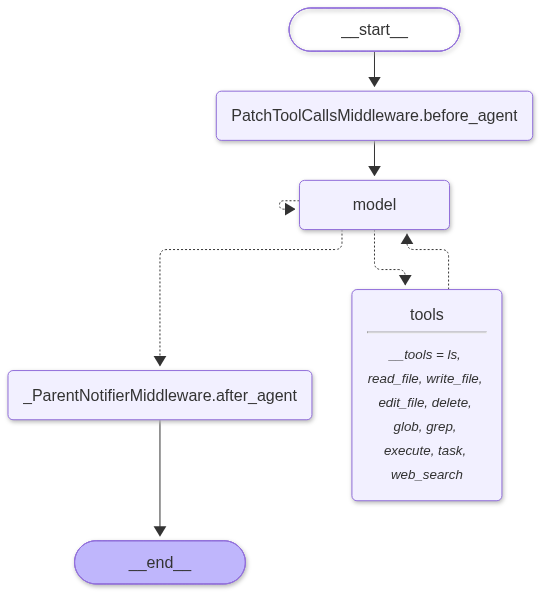

In [33]:
### Create a deep agent
## Prompt

## agent

from deepagents import create_deep_agent

deepagent=create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt="Act as a researcher"
)
deepagent

In [27]:
result = deepagent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

{'messages': [HumanMessage(content='What is deepagent?', additional_kwargs={}, response_metadata={}, id='73c9a25b-b834-4c78-ac61-3ad308540e3d'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': '6acm9kepc', 'function': {'arguments': '{"query":"deepagent"}', 'name': 'web_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 2850, 'total_tokens': 2877, 'completion_time': 0.076130968, 'completion_tokens_details': None, 'prompt_time': 0.257811064, 'prompt_tokens_details': None, 'queue_time': 2.905428138, 'total_time': 0.333942032}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_4560dae850', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1eec1-fdae-7005-bfdc-4073ba85215d-0', tool_calls=[{'name': 'web_search', 'args': {'query': 'deepagent'}, 'id': '6acm9kepc', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens':

In [32]:
result["messages"][-1].content

'**DeepAgent** most likely refers to **Deep Agents** (often written `deepagents`), an open-source agent library by LangChain. Here\'s a summary:\n\n## What it is\nDeep Agents is a "batteries-included" agent harness — a build on top of LangChain\'s `create_agent`, which itself sits on the LangGraph runtime. It\'s designed for **long-horizon, multi-step tasks** (research, coding, complex workflows) where you need planning, memory, and delegation out of the box.\n\n## Key features\n- **Subagents** — three built-ins: `research()`, `plan()`, and `general()`, plus optional background dispatch\n- **Persistent memory** — a `memory()` tool for retaining state across long runs\n- **Structured planning** — a `todo_write()` planning tool\n- **Context management** — middleware that compresses conversation history, offloads large tool results, isolates context with subagents, and uses prompt caching\n- **Filesystem tools** — bundled in, unlike the minimal LangChain harness\n- **Opinionated system pr

In [34]:
result['files']

{}

### What happened?

Your deep agent automatically:
- Planned its approach: Used the built-in write_todos tool to break down the research task
- Conducted research: Called the internet_search tool to gather information
- Managed context: Used file system tools (write_file, read_file) to offload large search results
- Spawned subagents (if needed): Delegated complex subtasks to specialized subagents
- Synthesized a report: Compiled findings into a coherent response

### Customizing Deep Agents

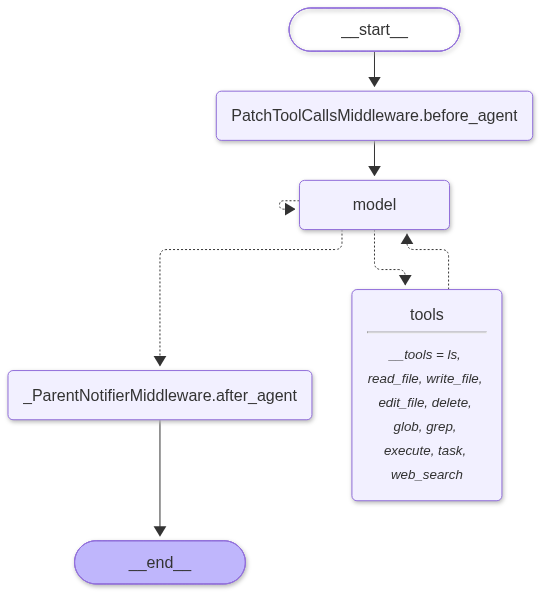

In [40]:
## #Model
from langchain.chat_models import init_chat_model
from deepagents import create_deep_agent

model = init_chat_model(
    model="qwen/qwen3.8-27b",
    model_provider="groq"
)
agent = create_deep_agent(model=model, tools=[web_search], system_prompt="Act as a researcher")
agent

In [36]:
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

BadRequestError: Error code: 400 - {'error': {'message': "tool call validation failed: parameters for tool grep did not match schema: errors: [missing properties: 'pattern']", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '<tool_call>\n<function=grep>\n< parameter=deepagent\n</parameter>\n</function>\n</tool_call>'}}

### System Prompt
Deep agents come with a built-in system prompt inspired by Claude Code’s system prompt. The default system prompt contains detailed instructions for using the built-in planning tool, file system tools, and subagents.
Each deep agent tailored to a use case should include a custom system prompt specific to that use case.

In [41]:
from deepagents import create_deep_agent

research_instructions = """\
You are an expert researcher. Your job is to conduct \
thorough research, and then write a polished report. \
"""

agent = create_deep_agent(
    model=model,
    tools=[web_search],
    system_prompt=research_instructions,
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent?"}]})
result

APIStatusError: Error code: 413 - {'error': {'message': 'Request too large for model `qwen/qwen3.8-27b` in organization `org_01m6672698e4krfndxagxedrxq` service tier `on_demand` on input tokens per minute (ITPM): Limit 7000, Requested 8974, please reduce your message size and try again. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing', 'type': 'tokens', 'code': 'rate_limit_exceeded'}}

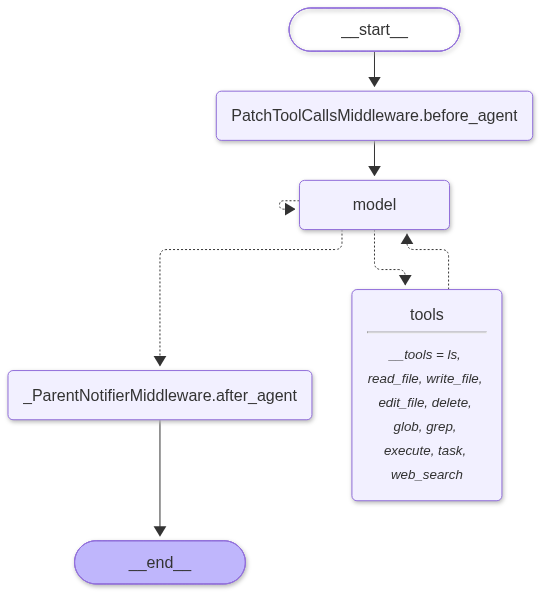

In [42]:
agent

In [43]:
### Tools
import os
from typing import Literal
from tavily import TavilyClient
from deepagents import create_deep_agent

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False,
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic,
    )

agent = create_deep_agent(
    model=model,
    tools=[internet_search]
)
result = agent.invoke({"messages": [{"role": "user", "content": "What is deepagent in Agentic AI?"}]})
result

{'messages': [HumanMessage(content='What is deepagent in Agentic AI?', additional_kwargs={}, response_metadata={}, id='55782b11-c2f6-4360-99c9-12ee714d3a04'),
  AIMessage(content='', additional_kwargs={'tool_calls': [{'id': 'na8zhwey0', 'function': {'arguments': '{"query":"deepagent Agentic AI what is it"}', 'name': 'internet_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 33, 'prompt_tokens': 2846, 'total_tokens': 2879, 'completion_time': 0.101526114, 'completion_tokens_details': None, 'prompt_time': 0.202495465, 'prompt_tokens_details': None, 'queue_time': 0.067611494, 'total_time': 0.304021579}, 'model_name': 'qwen/qwen3.8-27b', 'system_fingerprint': 'fp_424cb89518', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1eec9-a7b9-71e2-a542-1f66a353bc74-0', tool_calls=[{'name': 'internet_search', 'args': {'query': 'deepagent Agentic AI what is it'}, 'id': 'na8zhwey0', 'type': '